# 02 · Exact TSP

How far do exact methods actually reach? We solve the TSP to the **provable** optimum as a
mixed-integer program (MILP) with Miller-Tucker-Zemlin subtour elimination, solved by the open
CBC solver. We validate it against brute force where both run, then push the size up and watch
the same factorial wall arrive — this time in a real solver, on a 2-CPU machine.

Figures land in `outputs/figures/`, numbers in `outputs/data/`.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt

from src.evaluation.scaling import time_call
from src.exact.brute_force import brute_force_tsp
from src.exact.milp_tsp import milp_tsp
from src.problems.tsp import generate_tsp_instance, is_valid_tour
from src.reporting import save_figure, save_json
from src.visualisation import plot_tour

SEED = 42
TIME_LIMIT = 15.0  # every MILP solve is capped so the notebook stays bounded

## 1. MILP equals the true optimum

On instances small enough for brute force, the MILP must return exactly the same tour length.
We assert it — this is a success criterion of the project.

In [2]:
validation = []
for n in [5, 6, 7, 8, 9]:
    instance = generate_tsp_instance(n, seed=SEED)
    _, brute_length = brute_force_tsp(instance.distances)
    milp_route, milp_length = milp_tsp(instance.distances, time_limit=TIME_LIMIT)
    assert is_valid_tour(milp_route, n)
    assert abs(milp_length - brute_length) < 1e-6
    validation.append({"stops": n, "brute_force": brute_length, "milp": milp_length,
                       "match": True})
    print(f"n={n}: brute={brute_length:.4f}  milp={milp_length:.4f}  ✓ match")

save_json("02_milp_vs_brute_force", {"seed": SEED, "rows": validation})

n=5: brute=226.9425  milp=226.9425  ✓ match
n=6: brute=227.1876  milp=227.1876  ✓ match
n=7: brute=227.2035  milp=227.2035  ✓ match
n=8: brute=240.4857  milp=240.4857  ✓ match


n=9: brute=264.4521  milp=264.4521  ✓ match


PosixPath('/workspaces/routing_arena/outputs/data/02_milp_vs_brute_force.json')

## 2. A proven-optimal tour

The exact optimum for one 12-stop instance, drawn.

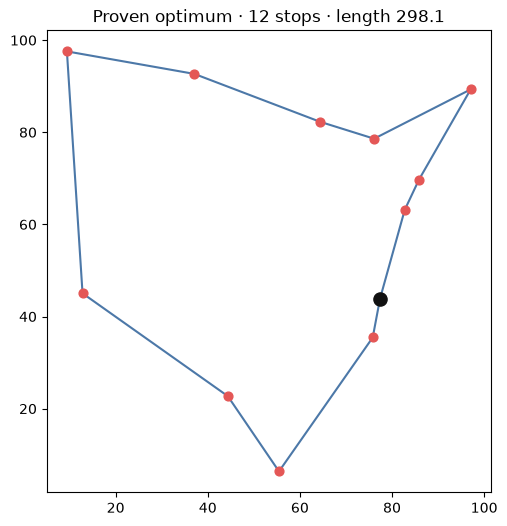

PosixPath('/workspaces/routing_arena/outputs/data/02_optimal_tour_n12.json')

In [3]:
instance = generate_tsp_instance(12, seed=SEED)
opt_route, opt_length = milp_tsp(instance.distances, time_limit=TIME_LIMIT)
fig, ax = plt.subplots(figsize=(6, 6))
plot_tour(instance, opt_route, ax=ax, title=f"Proven optimum · 12 stops · length {opt_length:.1f}")
save_figure(fig, "02_optimal_tour_n12")
plt.show()

save_json("02_optimal_tour_n12", {"stops": 12, "seed": SEED, "optimal_length": opt_length,
                                  "tour": opt_route})

## 3. The exact frontier

Now push the size up. CBC on the MTZ formulation is instant for a dozen stops, then solve time
climbs steeply and erratically. Each solve is capped at 15 s; past the high teens on 2 CPUs the
exact approach is no longer practical, which is exactly the point.

In [4]:
sizes = [6, 8, 10, 12, 14, 16, 18]
scaling = []
for n in sizes:
    instance = generate_tsp_instance(n, seed=SEED)
    (route, length), seconds = time_call(
        lambda inst=instance: milp_tsp(inst.distances, time_limit=TIME_LIMIT))
    scaling.append({"stops": n, "seconds": seconds, "length": length,
                    "hit_time_limit": seconds >= TIME_LIMIT})
    print(f"n={n:>2} -> {seconds:7.3f} s   length {length:7.2f}")

save_json("02_exact_scaling", {"seed": SEED, "time_limit_seconds": TIME_LIMIT, "rows": scaling})

n= 6 ->   0.026 s   length  227.19
n= 8 ->   0.030 s   length  240.49
n=10 ->   0.105 s   length  264.53


n=12 ->   0.143 s   length  298.06
n=14 ->   0.187 s   length  312.35


n=16 ->   0.275 s   length  331.47


n=18 ->   1.183 s   length  333.37


PosixPath('/workspaces/routing_arena/outputs/data/02_exact_scaling.json')

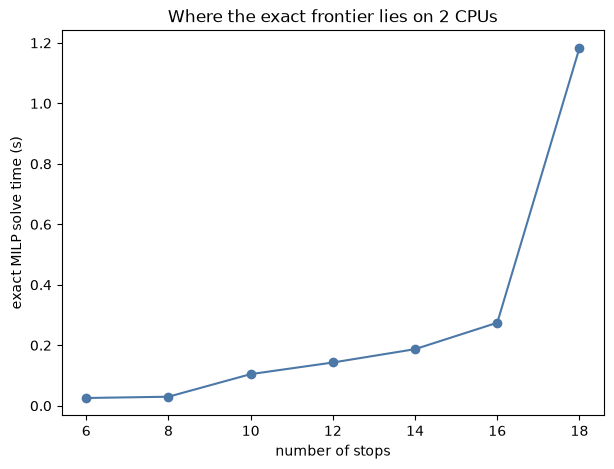

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot([r["stops"] for r in scaling], [r["seconds"] for r in scaling], "-o", color="#4C78A8")
ax.set_xlabel("number of stops")
ax.set_ylabel("exact MILP solve time (s)")
ax.set_title("Where the exact frontier lies on 2 CPUs")
save_figure(fig, "02_exact_scaling")
plt.show()

## Takeaway

Exact is real and useful — up to a point. On this machine that point is in the high teens of
stops. Beyond it, optimality is not an option **regardless of solver quality**, because the search
space is the factorial curve from notebook 01. So we stop chasing the optimum and start measuring
how close a cheap heuristic can get to it.

Next: **03 · Construction Heuristics** — a complete, usable route in ten lines of code, and
exactly how far from optimal it lands.